In [2]:
import pandas as pd
import numpy as np

## Data preprocessing

In [5]:
#Load the dataset
df = pd.read_csv("/home/ander/Documentos/Universidad/ML/proyecto/Datasets/train_processed.csv")

In [6]:
observations, variables = df.shape
print(f"Observations: {observations}, Variables: {variables}")
df.info()


Observations: 15000, Variables: 11
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      15000 non-null  float64
 1   Geography        15000 non-null  object 
 2   Gender           15000 non-null  object 
 3   Age              15000 non-null  float64
 4   Tenure           15000 non-null  float64
 5   Balance          15000 non-null  float64
 6   NumOfProducts    15000 non-null  float64
 7   HasCrCard        15000 non-null  float64
 8   IsActiveMember   15000 non-null  float64
 9   EstimatedSalary  15000 non-null  float64
 10  Exited           15000 non-null  float64
dtypes: float64(9), object(2)
memory usage: 1.3+ MB


In [4]:
df.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15709511.0,Ch'ang,754.0,Spain,Male,40.0,8.0,102954.68,2.0,1.0,1.0,149238.35,0.0
1,1,15592761.0,Genovese,579.0,France,Female,28.0,1.0,0.00,2.0,1.0,0.0,64869.32,0.0
2,2,15579914.0,Yeh,744.0,France,Female,56.0,5.0,0.00,1.0,1.0,0.0,158816.03,1.0
3,3,15669611.0,Nwachinemelu,697.0,France,Male,29.0,2.0,0.00,2.0,1.0,0.0,55775.72,0.0
4,4,15761775.0,Hs?eh,628.0,France,Female,22.0,9.0,0.00,2.0,1.0,0.0,49653.39,0.0


In [5]:
# Drop id and surname columns
df.drop(columns=['id', 'CustomerId','Surname'], inplace=True)



In [6]:
# Columnas resultantes
print(df.columns.tolist())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']



## EDA

#### Basic descriptive statistics

In [7]:
# Numerical variables
num_cols = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'Tenure']
df[num_cols].describe()


,Age,Balance,CreditScore,EstimatedSalary,Tenure
count,15000.000000,15000.000000,15000.000000,1.500000e+04,15000.000000
mean,37.888000,43124.060479,658.851467,1.181348e+05,5.033333
std,8.257409,59777.868496,72.587026,4.680311e+04,2.808359
min,18.000000,0.000000,431.000000,1.158000e+01,0.000000
25%,32.000000,0.000000,602.000000,8.362960e+04,3.000000
50%,37.000000,0.000000,662.000000,1.235878e+05,5.000000
75%,42.000000,109650.982500,709.000000,1.575585e+05,7.000000
max,74.000000,187530.660000,850.000000,1.557802e+06,10.000000


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      15000 non-null  float64
 1   Geography        15000 non-null  object 
 2   Gender           15000 non-null  object 
 3   Age              15000 non-null  float64
 4   Tenure           15000 non-null  float64
 5   Balance          15000 non-null  float64
 6   NumOfProducts    15000 non-null  float64
 7   HasCrCard        15000 non-null  float64
 8   IsActiveMember   15000 non-null  float64
 9   EstimatedSalary  15000 non-null  float64
 10  Exited           15000 non-null  float64
dtypes: float64(9), object(2)
memory usage: 1.3+ MB


In [9]:
cat_cols = ['Geography', 'Gender', 'HasCrCard', 'IsActiveMember', 'Exited', 'NumOfProducts']
df_categorical = df[cat_cols]
ala = df_categorical.describe()

#Frecuencias relativas variables categóricas
for col in df_categorical.columns:
    print(f"Frecuencias relativas de {col}:")
    print(df_categorical[col].value_counts(normalize=True))
    print()

Frecuencias relativas de Geography:
Geography
France     0.598067
Spain      0.221400
Germany    0.180533
Name: proportion, dtype: float64

Frecuencias relativas de Gender:
Gender
Male      0.5572
Female    0.4428
Name: proportion, dtype: float64

Frecuencias relativas de HasCrCard:
HasCrCard
1.0    0.7832
0.0    0.2168
Name: proportion, dtype: float64

Frecuencias relativas de IsActiveMember:
IsActiveMember
1.0    0.5002
0.0    0.4998
Name: proportion, dtype: float64

Frecuencias relativas de Exited:
Exited
0.0    0.796133
1.0    0.203867
Name: proportion, dtype: float64

Frecuencias relativas de NumOfProducts:
NumOfProducts
2.0    0.553667
1.0    0.429133
3.0    0.014533
4.0    0.002667
Name: proportion, dtype: float64



<Figure size 1200x800 with 0 Axes>

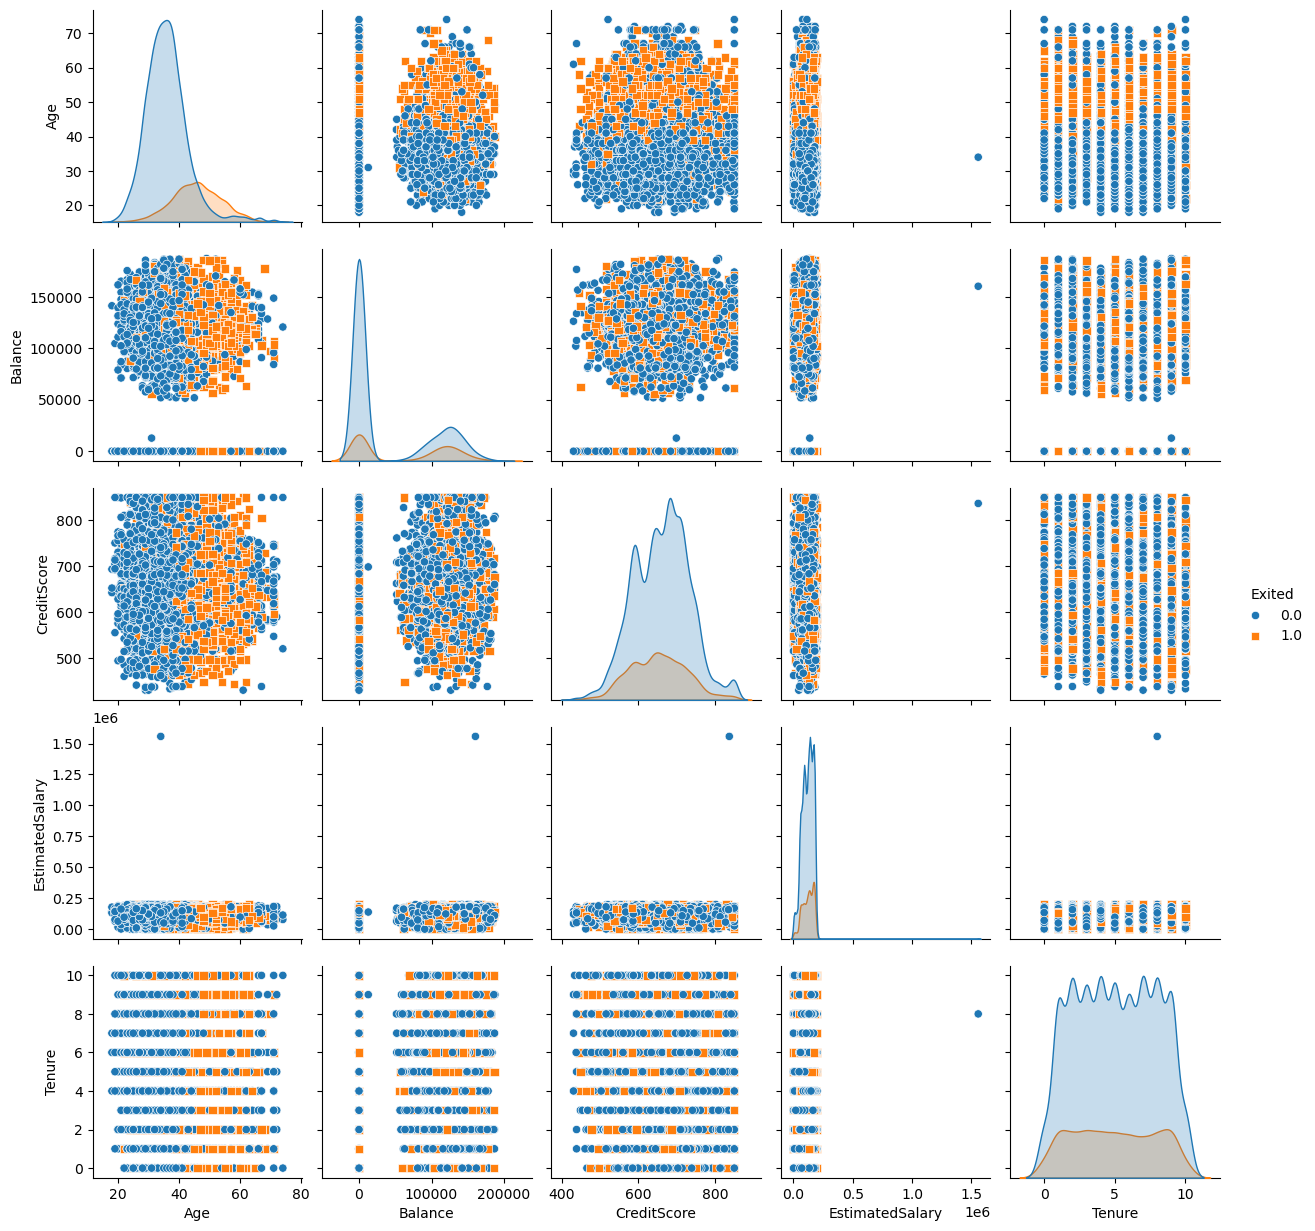

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'Tenure']
df_numerical = df[num_cols].copy()
df_numerical['Exited'] = df['Exited']
plt.figure(figsize=(12, 8))
sns.pairplot(df_numerical, diag_kind='kde', hue='Exited', markers=["o", "s"])
plt.show()

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Variables categóricas
cat_cols = ['Geography', 'Gender', 'HasCrCard', 'IsActiveMember', 'Exited', 'NumOfProducts']
df_categorical = df[cat_cols].copy()

# Cambia los valores para mayor claridad en los gráficos
df_categorical['Exited'] = df_categorical['Exited'].map({0: 'Stayed', 1: 'Exited'})
df_categorical['HasCrCard'] = df_categorical['HasCrCard'].map({0: 'No', 1: 'Yes'})
df_categorical['IsActiveMember'] = df_categorical['IsActiveMember'].map({0: 'No', 1: 'Yes'})

# Obtén el total de observaciones
n_total = len(df_categorical)

# Lista de columnas a graficar
categorical_columns = [col for col in df_categorical.columns if col != 'Exited']

# Paleta de colores (definida una sola vez)
custom_palette = {'Stayed': '#4F6A90', 'Exited': '#6ACC6D'}

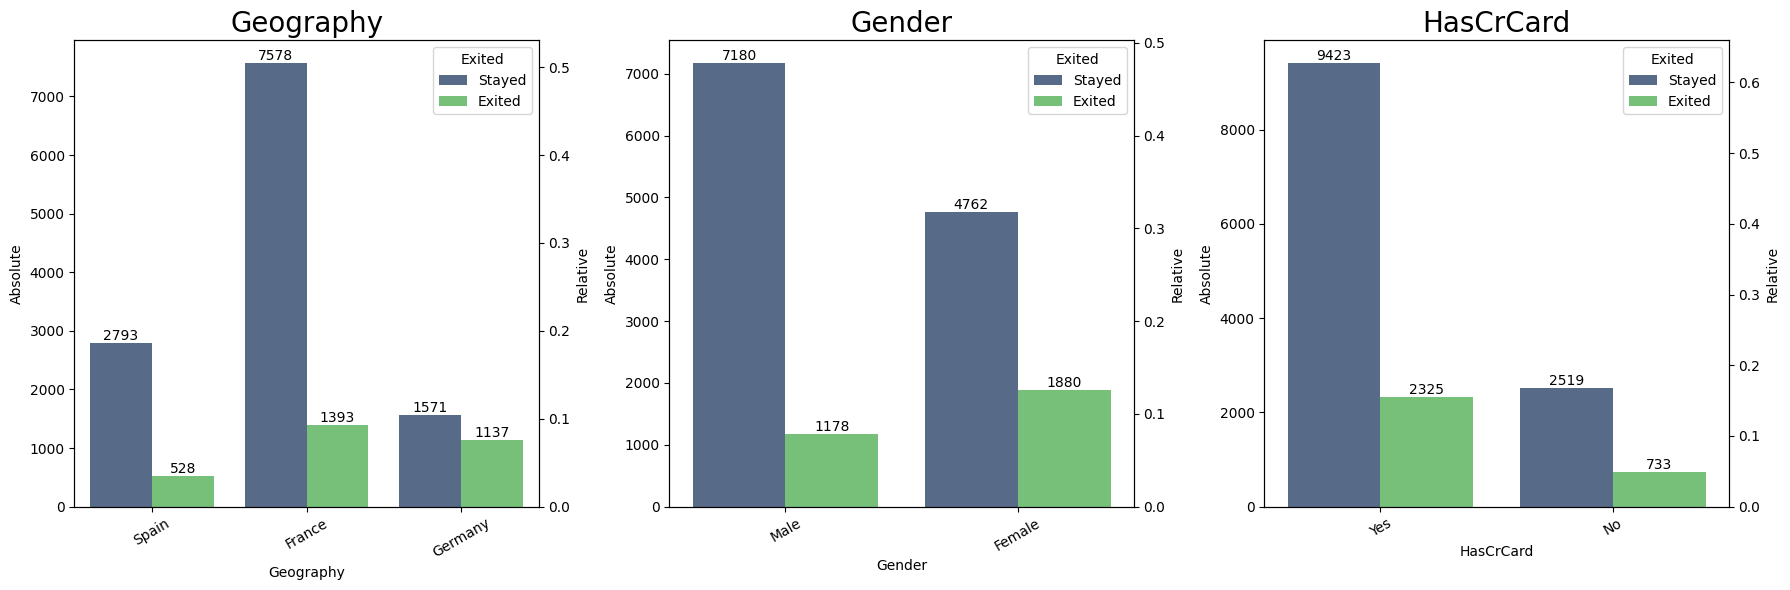

In [13]:
# --- GRÁFICO 1: PRIMERAS 3 VARIABLES ---

# Creamos una figura con una fila y tres columnas
fig1, axes1 = plt.subplots(1, 3, figsize=(18, 6))

# Usamos slicing [:3] para tomar solo las primeras 3 columnas
for i, column in enumerate(categorical_columns[:3]):
    ax = axes1[i]
    sns.countplot(data=df_categorical, x=column, ax=ax, hue='Exited', palette=custom_palette)
    
    ax.set_title(f'{column}', fontsize=20)
    ax.tick_params(axis='x', rotation=30)
    ax.set_ylabel('Absolute')

    ax2 = ax.twinx()
    for bars in ax.containers:
        ax.bar_label(bars)

    y_max = ax.get_ylim()[1]
    ax2.set_ylim(0, y_max / n_total)
    ax2.set_ylabel('Relative')

plt.tight_layout()
plt.show()

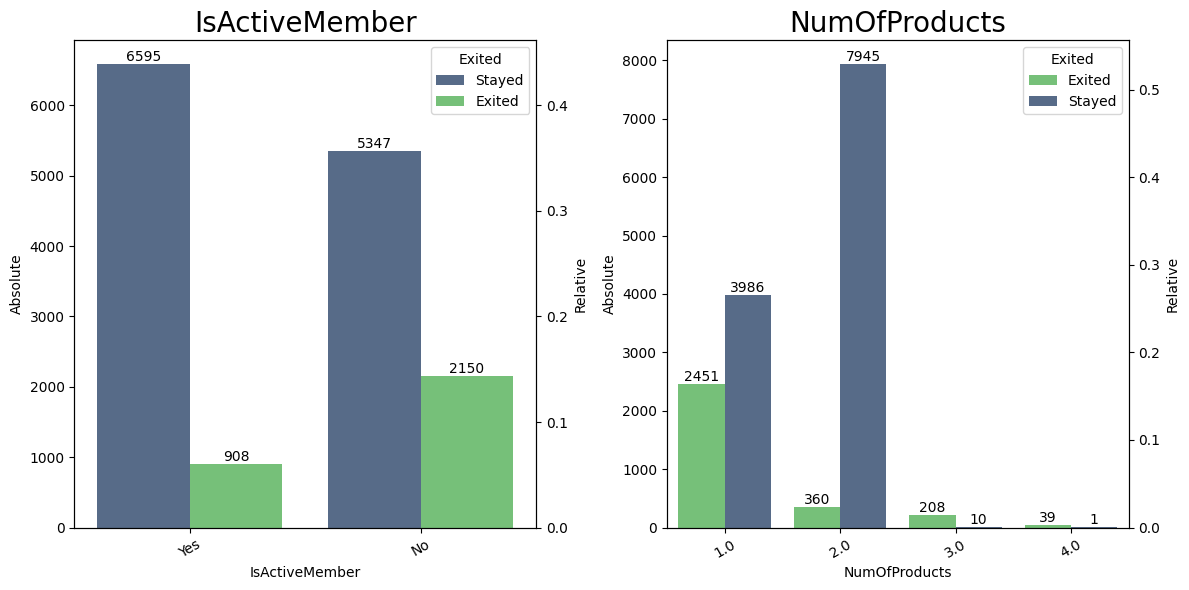

In [14]:
# --- GRÁFICO 2: ÚLTIMAS 2 VARIABLES ---

# Creamos una figura con una fila y dos columnas
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 6))
# Aplanamos el array de ejes para poder iterar fácilmente
axes2 = axes2.flatten() 

# Usamos slicing [3:] para tomar las columnas desde el índice 3 hasta el final
for i, column in enumerate(categorical_columns[3:]):
    ax = axes2[i]
    sns.countplot(data=df_categorical, x=column, ax=ax, hue='Exited', palette=custom_palette)
    
    ax.set_title(f'{column}', fontsize=20)
    ax.tick_params(axis='x', rotation=30)
    ax.set_ylabel('Absolute')

    ax2 = ax.twinx()
    for bars in ax.containers:
        ax.bar_label(bars)

    y_max = ax.get_ylim()[1]
    ax2.set_ylim(0, y_max / n_total)
    ax2.set_ylabel('Relative')

plt.tight_layout()
plt.show()

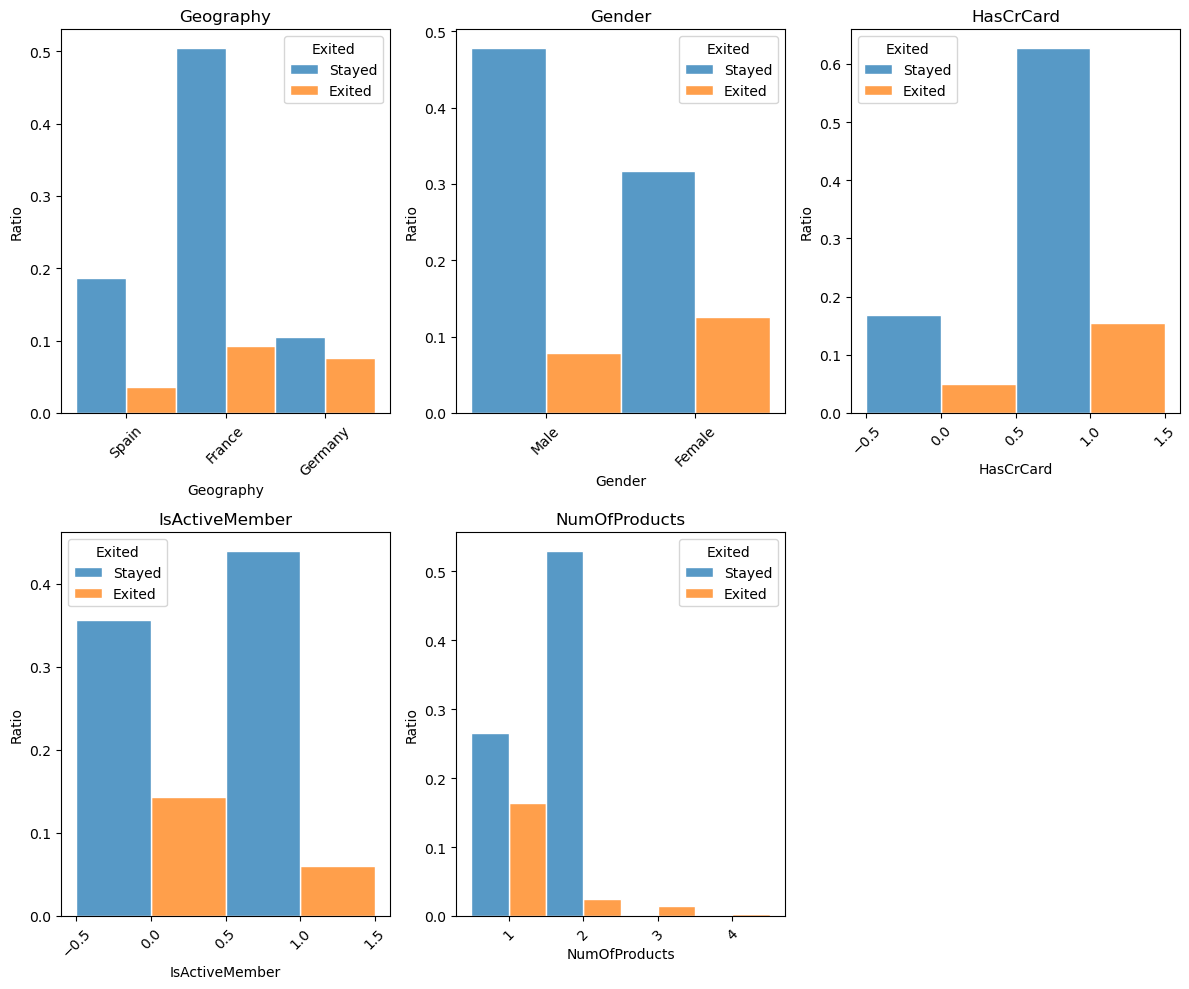

In [12]:
# Categorical variables
df_categorical = df[cat_cols].copy()
df_categorical['Exited'] = df_categorical['Exited'].map({0: 'Stayed', 1: 'Exited'})

# Get categorical columns excluding 'Exited'
categorical_columns = cat_cols.copy()
categorical_columns.remove('Exited')

import matplotlib.pyplot as plt
import seaborn as sns

n_cols = 3
n_rows = 2
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 10))
axes = axes.ravel()

custom_palette = {'Stayed': '#1f77b4', 'Exited': 'orange'}

for i, column in enumerate(categorical_columns):
    if i < len(axes):
        sns.histplot(
            data=df_categorical,
            x=column,
            hue='Exited',
            multiple='dodge',
            discrete=True,
            ax=axes[i],
            edgecolor='w',
            stat='probability',
        )
        axes[i].set_title(column)
        axes[i].set_xlabel(column)
        axes[i].set_ylabel('Ratio')
        axes[i].tick_params(axis='x', rotation=45)

# Hide unused subplots
for j in range(len(categorical_columns), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()



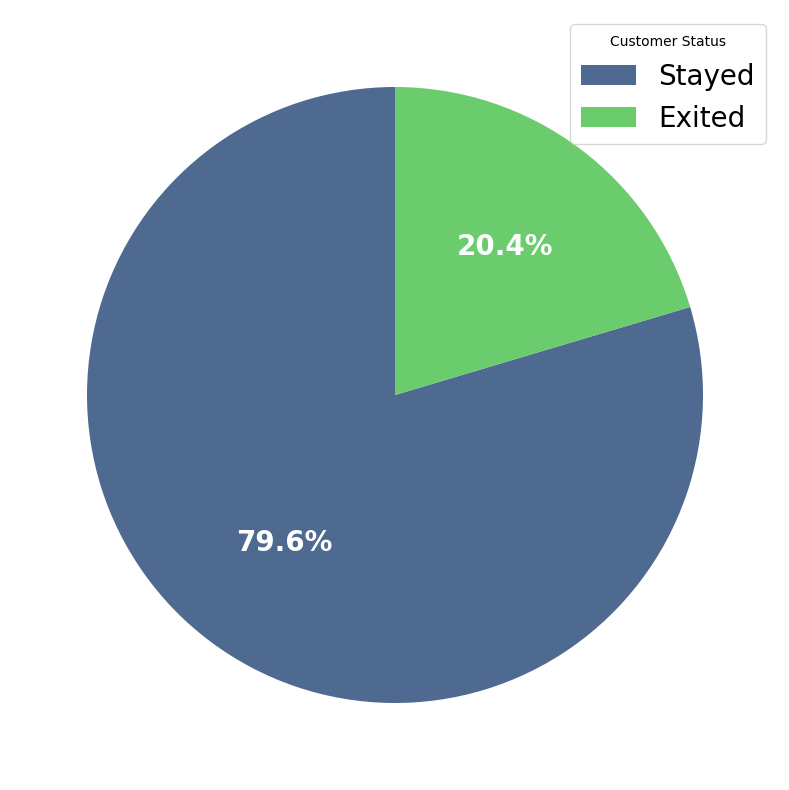

In [18]:
# 1. Define la paleta de colores
custom_palette = {'Stayed': '#4F6A90', 'Exited': '#6ACC6D'}

# 2. Obtén las cuentas y asegúrate de que los colores coincidan con el orden de las etiquetas
exit_counts = df_categorical['Exited'].value_counts(normalize=True)
colors_for_pie = [custom_palette[key] for key in exit_counts.index]

# 3. Grafica usando el parámetro 'colors'
plt.figure(figsize=(12, 8))

plt.pie(
    exit_counts.values,
    labels=exit_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors_for_pie,  # <-- Aquí se aplica la paleta de colores
    textprops={'color': 'white', 'fontsize': 20, 'weight': 'bold'}
)

plt.legend(title='Customer Status', loc='upper right', fontsize=20) # Ajusté el fontsize para que se vea mejor

plt.tight_layout()
plt.show()

#### Outliers

In [14]:
from scipy import stats

num_cols = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'Tenure']
df_numerical = df[num_cols].copy()

def detect_outliers_zscore(data, column, threshold=3):
    z_scores = np.abs(stats.zscore(data[column]))
    outliers = data[z_scores > threshold]

    print(f"Variable: {column}")
    print(f"Z-score > {threshold}: {len(outliers)} ({len(outliers)/len(data)*100:.2f}%)")

    return outliers

# Aplicar Z-score a variables numéricas
for column in df_numerical.columns:
    outliers_zscore = detect_outliers_zscore(df, column)

df_numerical['Exited'] = df['Exited'].astype(bool)

Variable: Age
Z-score > 3: 150 (1.00%)
Variable: Balance
Z-score > 3: 0 (0.00%)
Variable: CreditScore
Z-score > 3: 15 (0.10%)
Variable: EstimatedSalary
Z-score > 3: 1 (0.01%)
Variable: Tenure
Z-score > 3: 0 (0.00%)


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Lista de columnas numéricas a graficar
num_cols = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'Tenure']

# Preparación del DataFrame para el gráfico
num_df = df[num_cols].copy()
num_df['Exited'] = df['Exited']
num_df['Exited'] = num_df['Exited'].map({0: 'Stayed', 1: 'Exited'})

# Definición de la paleta de colores
custom_palette = {'Stayed': '#4F6A90', 'Exited': '#6ACC6D'}

print("Datos preparados. Listo para generar los gráficos.")

Datos preparados. Listo para generar los gráficos.


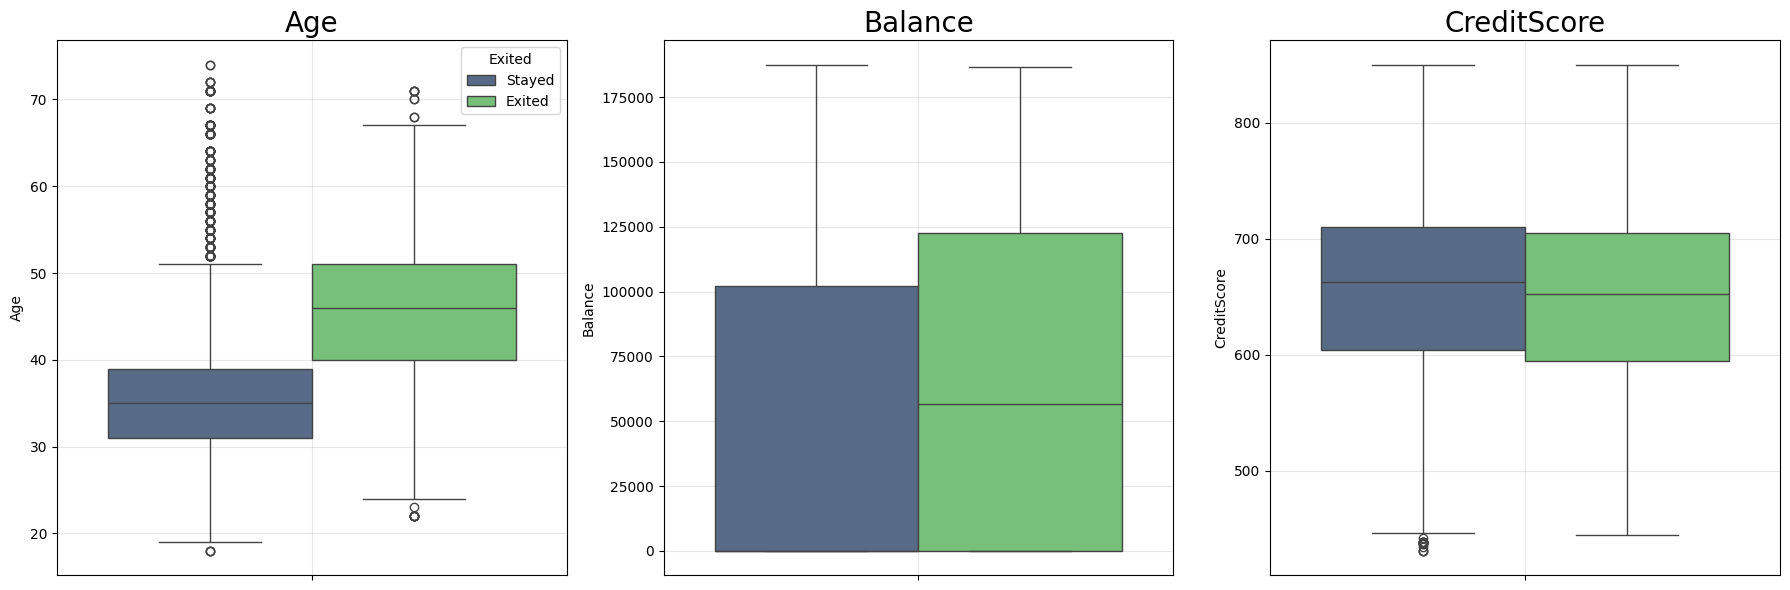

In [22]:
# --- GRÁFICO 1: PRIMERAS 3 VARIABLES NUMÉRICAS ---

# Creamos una figura con 1 fila y 3 columnas
fig1, axes1 = plt.subplots(1, 3, figsize=(18, 6))
axes1 = axes1.ravel()

# Usamos slicing [:3] para tomar solo las primeras 3 columnas de la lista num_cols
for i, column in enumerate(num_cols[:3]):
    sns.boxplot(data=num_df, y=column, ax=axes1[i], hue='Exited', palette=custom_palette)
    axes1[i].set_title(f'{column}', fontsize=20)
    axes1[i].grid(True, alpha=0.3)
    
    # Mostrar la leyenda solo en el primer subplot de esta figura
    if i == 0:
        axes1[i].legend(title='Exited', loc='upper right')
    else:
        axes1[i].get_legend().remove()

plt.tight_layout()
plt.show()

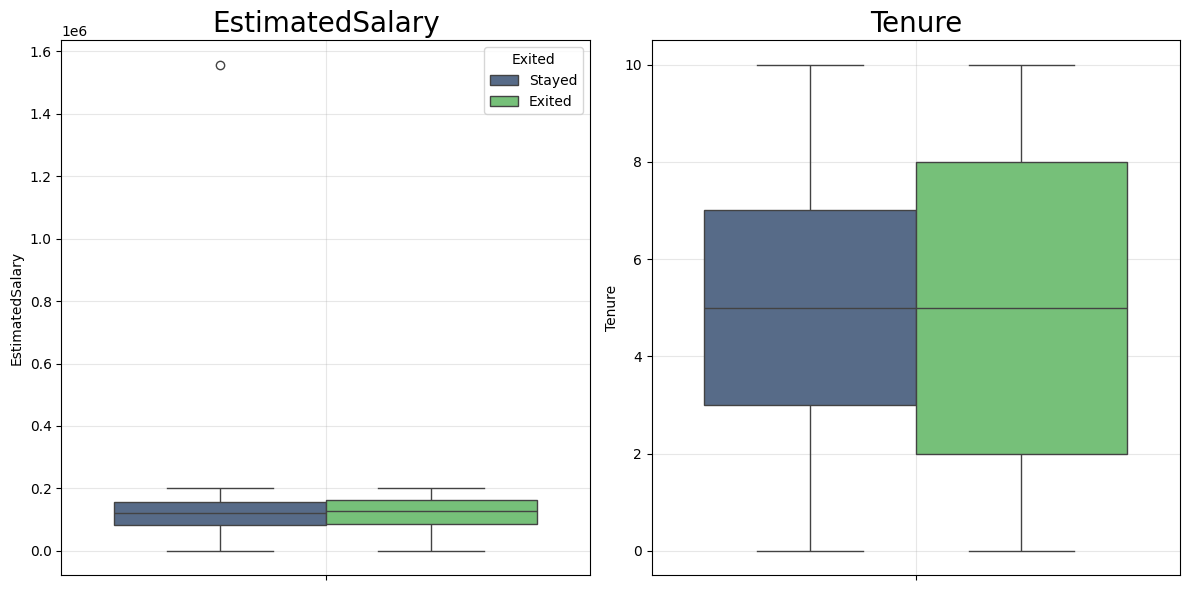

In [23]:
# --- GRÁFICO 2: ÚLTIMAS 2 VARIABLES NUMÉRICAS ---

# Creamos una figura con 1 fila y 2 columnas
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 6))
axes2 = axes2.ravel()

# Usamos slicing [3:] para tomar las columnas restantes
for i, column in enumerate(num_cols[3:]):
    sns.boxplot(data=num_df, y=column, ax=axes2[i], hue='Exited', palette=custom_palette)
    axes2[i].set_title(f'{column}', fontsize=20)
    axes2[i].grid(True, alpha=0.3)
    
    # La lógica de la leyenda funciona igual aquí: se mostrará en el primer
    # gráfico de *esta* nueva figura (cuando i sea 0 para este bucle)
    if i == 0:
        axes2[i].legend(title='Exited', loc='upper right')
    else:
        axes2[i].get_legend().remove()

plt.tight_layout()
plt.show()

Delete outliers

In [16]:
from scipy import stats

num_cols   = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'Tenure']
z_scores = np.abs(stats.zscore(df[num_cols]))
mask = (z_scores < 3).all(axis=1)
df_cleaned = df[mask].copy()


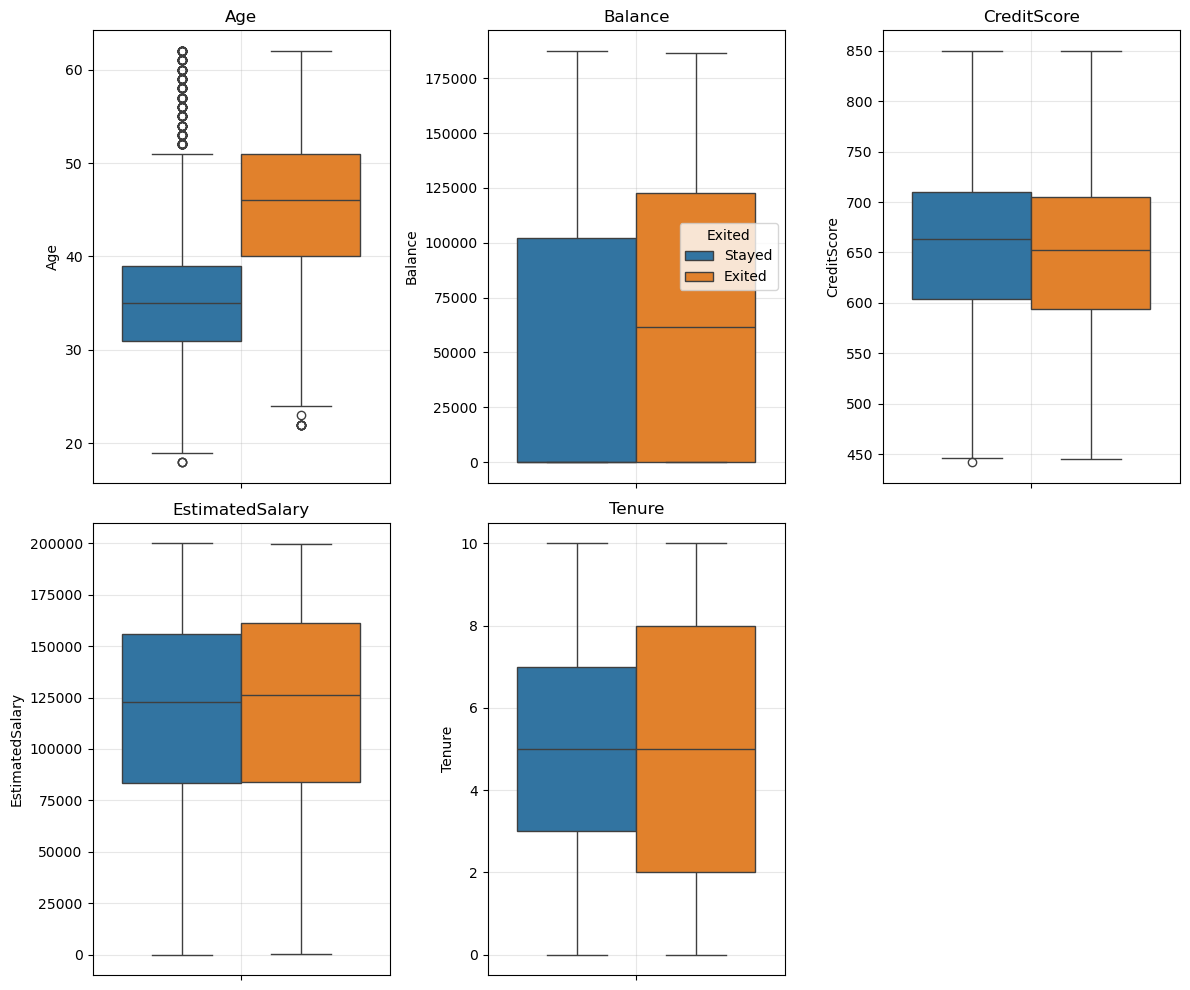

In [17]:
# Box plots para visualizar outliers
num_cols = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'Tenure']

num_df = df_cleaned[num_cols].copy()
num_df['Exited'] = df_cleaned['Exited']
num_df['Exited'] = num_df['Exited'].map({0: 'Stayed', 1: 'Exited'})


cols = 3
rows = len(num_cols) // cols + (len(num_cols) % cols > 0)

fig, axes = plt.subplots(2,3, figsize=( 4*cols, 5*rows))
axes = axes.ravel()


for i, column in enumerate(num_cols):
    if i < len(axes):
        sns.boxplot(data=num_df, y=column, ax=axes[i], hue='Exited')
        axes[i].set_title(f'{column}')
        axes[i].grid(True, alpha=0.3)
        if i == 1:  # Solo mostrar la leyenda en el primer subplot
            axes[i].legend(title='Exited')
        else:
            axes[i].get_legend().remove()
        

for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)


plt.tight_layout()
plt.show()

#### Distribution analysis

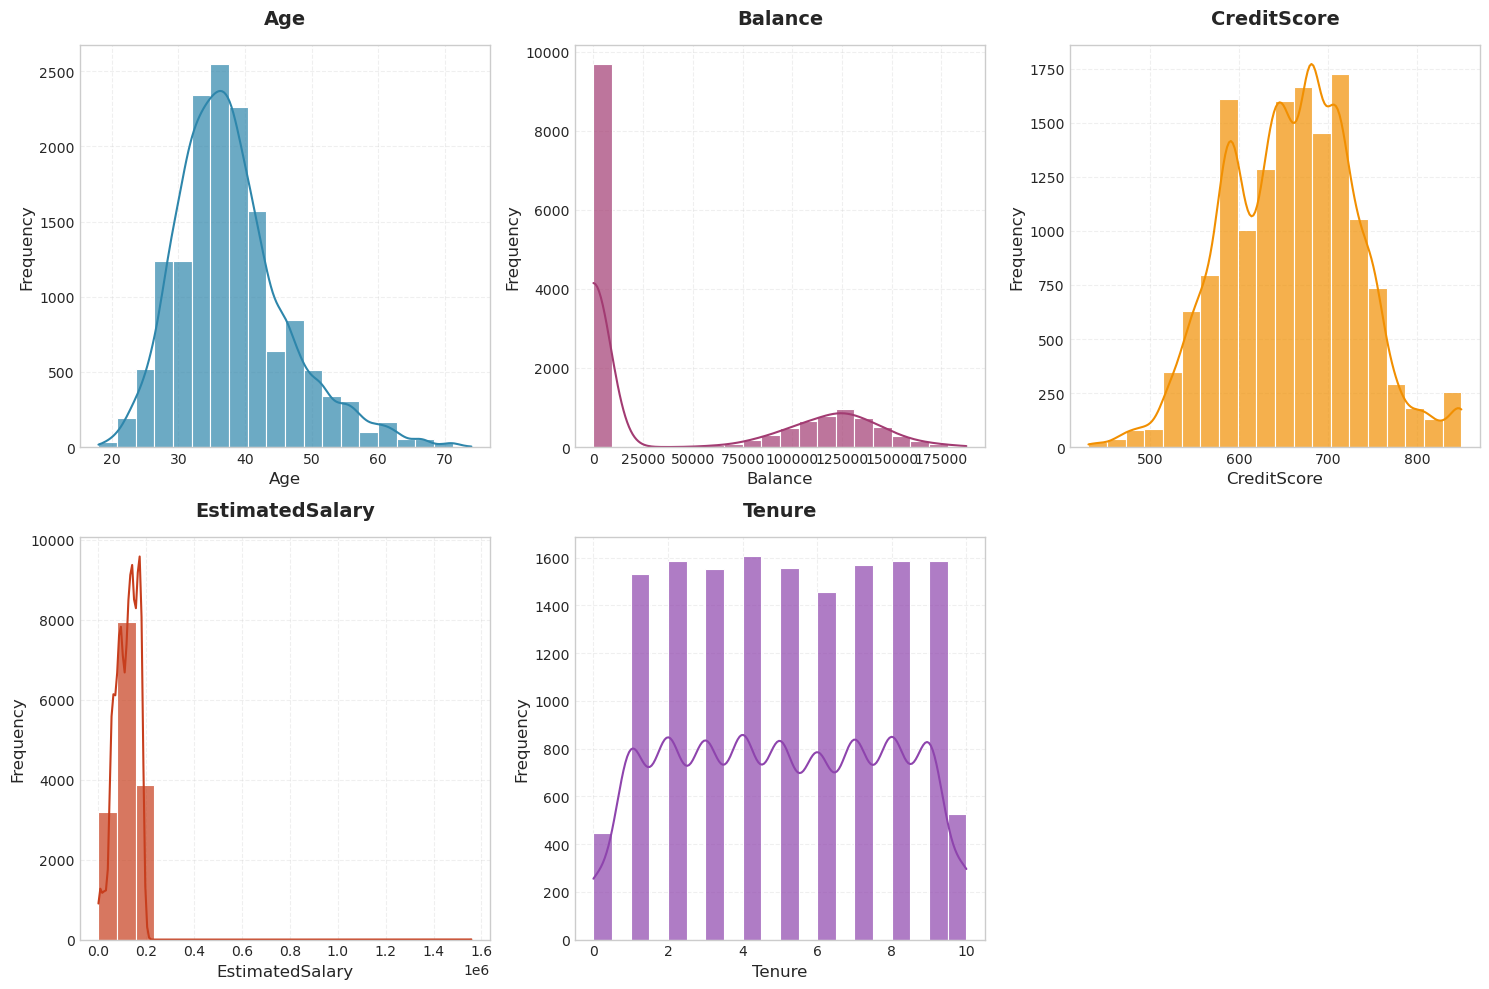

In [18]:
# ...existing code...
# Distribution analysis
plt.style.use('seaborn-v0_8-whitegrid')

numerical_columns = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'Tenure']
colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#8E44AD']

n_cols = 3
n_vars = len(numerical_columns)
n_rows = n_vars // n_cols + int(n_vars % n_cols > 0)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axes = axes.ravel()

for i, column in enumerate(numerical_columns):
    sns.histplot(data=df, x=column, kde=True, ax=axes[i], bins=20,
                 color=colors[i % len(colors)], alpha=0.7,
                 edgecolor='white', linewidth=0.8)
    axes[i].set_title(f'{column}', fontsize=14, fontweight='bold', pad=15)
    axes[i].set_xlabel(column, fontsize=12, fontweight='medium')
    axes[i].set_ylabel('Frequency', fontsize=12, fontweight='medium')
    axes[i].grid(True, alpha=0.3, linestyle='--')

# Oculta los ejes vacíos si hay menos de 4*n_rows variables
for j in range(n_vars, n_cols * n_rows):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

#### Linear Relationship Analysis

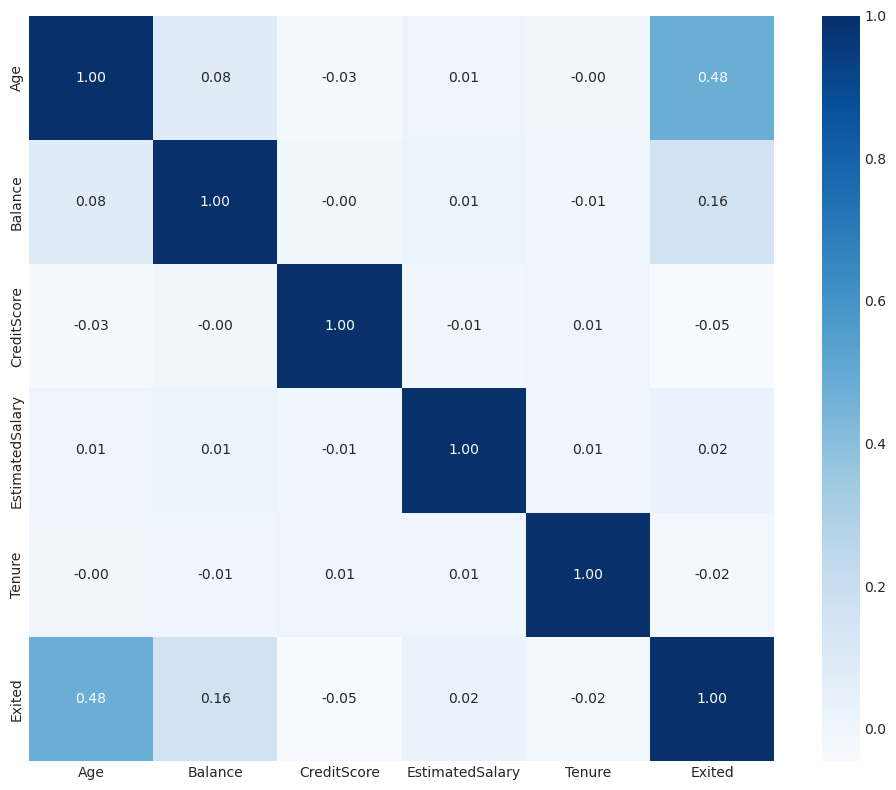

In [33]:
num_cols = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'Tenure']
df_numerical = df[num_cols].copy()
df_numerical['Exited'] = df['Exited']
#Correlation analysis
correlation_matrix = df_numerical.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", square=True, cmap= 'Blues')
plt.tight_layout()


#### Non-linear relationships analysis

In [105]:
num_cols = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'Tenure']
df_numerical = df_cleaned[num_cols].copy()
df_numerical['Exited'] = df['Exited']

#Non-parametric correlation
from scipy.stats import spearmanr
def spearman_correlation(data, column1, column2):
    correlation, p_value = spearmanr(data[column1], data[column2])
    print(f"Spearman correlation between {column1} and {column2}: {correlation:.2f}, p-value: {p_value:.4f}")

# Apply Spearman correlation to numerical variables
for i in range(len(df_numerical.columns)):
    for j in range(i + 1, len(df_numerical.columns)):
        col1 = df_numerical.columns[i]
        col2 = df_numerical.columns[j]
        spearman_correlation(df_numerical, col1, col2)


Spearman correlation between Age and Balance: 0.08, p-value: 0.0000
Spearman correlation between Age and CreditScore: -0.03, p-value: 0.0002
Spearman correlation between Age and EstimatedSalary: 0.01, p-value: 0.1314
Spearman correlation between Age and Tenure: 0.00, p-value: 0.5590
Spearman correlation between Age and Exited: 0.48, p-value: 0.0000
Spearman correlation between Balance and CreditScore: -0.00, p-value: 0.7935
Spearman correlation between Balance and EstimatedSalary: 0.01, p-value: 0.1108
Spearman correlation between Balance and Tenure: -0.01, p-value: 0.4713
Spearman correlation between Balance and Exited: 0.15, p-value: 0.0000
Spearman correlation between CreditScore and EstimatedSalary: -0.01, p-value: 0.1609
Spearman correlation between CreditScore and Tenure: 0.01, p-value: 0.1365
Spearman correlation between CreditScore and Exited: -0.05, p-value: 0.0000
Spearman correlation between EstimatedSalary and Tenure: 0.00, p-value: 0.7362
Spearman correlation between Estim

In [106]:
df_cleaned.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,754.0,Spain,Male,40.0,8.0,102954.68,2.0,1.0,1.0,149238.35,0.0
1,579.0,France,Female,28.0,1.0,0.00,2.0,1.0,0.0,64869.32,0.0
2,744.0,France,Female,56.0,5.0,0.00,1.0,1.0,0.0,158816.03,1.0
3,697.0,France,Male,29.0,2.0,0.00,2.0,1.0,0.0,55775.72,0.0
4,628.0,France,Female,22.0,9.0,0.00,2.0,1.0,0.0,49653.39,0.0


#### Save csv file

In [107]:
# Save the processed DataFrame to a new CSV file
df_cleaned.to_csv("/home/cristian/courses/machine_learning_UNAL/customer_churn_prediction/data/processed/train_processed_no_outliers.csv", index=False)